In [1]:
import torch

# Check available VRAM before loading
if torch.cuda.is_available():
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    reserved = torch.cuda.memory_reserved(0) / 1e9
    allocated = torch.cuda.memory_allocated(0) / 1e9
    free = total - reserved
    print(f"Total VRAM:     {total:.2f} GB")
    print(f"Reserved:       {reserved:.2f} GB")
    print(f"Allocated:      {allocated:.2f} GB")
    print(f"Free:           {free:.2f} GB")

Total VRAM:     4.29 GB
Reserved:       0.00 GB
Allocated:      0.00 GB
Free:           4.29 GB


In [2]:
import numpy as np
import pickle
from transformers import DistilBertForSequenceClassification, DistilBertTokenizer
from torch.nn.functional import softmax
from torch.utils.data import DataLoader
from datasets import load_dataset

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load saved model and tokenizer
model = DistilBertForSequenceClassification.from_pretrained('../results/baseline_model')
tokenizer = DistilBertTokenizer.from_pretrained('../results/baseline_model')
model = model.to(device)
model.eval()
print("Model loaded")

# Load and tokenize dataset
dataset = load_dataset("stanfordnlp/imdb", cache_dir="../data/imdb")

def tokenize(batch):
    return tokenizer(
        batch['text'],
        truncation=True,
        padding='max_length',
        max_length=512
    )

tokenized = dataset.map(tokenize, batched=True)
tokenized.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])
print("Dataset ready")

Using device: cuda


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset ready


In [3]:
all_logits, all_labels = [], []

with torch.no_grad():
    for batch in DataLoader(tokenized['test'], batch_size=32):
        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k in ['input_ids', 'attention_mask']
        }
        outputs = model(**inputs)
        all_logits.append(outputs.logits.cpu())
        all_labels.append(batch['label'])

logits = torch.cat(all_logits)
labels = torch.cat(all_labels)
probs  = softmax(logits, dim=-1)
confs  = probs.max(dim=-1).values
preds  = logits.argmax(dim=-1)

print(f"Total predictions: {len(preds)}")
print(f"Accuracy: {(preds == labels).float().mean():.4f}")
print(f"Mean confidence: {confs.mean():.4f}")
print(f"Min confidence:  {confs.min():.4f}")
print(f"Max confidence:  {confs.max():.4f}")

Total predictions: 25000
Accuracy: 0.9286
Mean confidence: 0.9857
Min confidence:  0.5005
Max confidence:  0.9991


In [4]:
with open('../results/baseline_predictions.pkl', 'wb') as f:
    pickle.dump({
        'probs':  probs,
        'preds':  preds,
        'labels': labels,
        'confs':  confs
    }, f)

print("Predictions saved to ../results/baseline_predictions.pkl")

Predictions saved to ../results/baseline_predictions.pkl


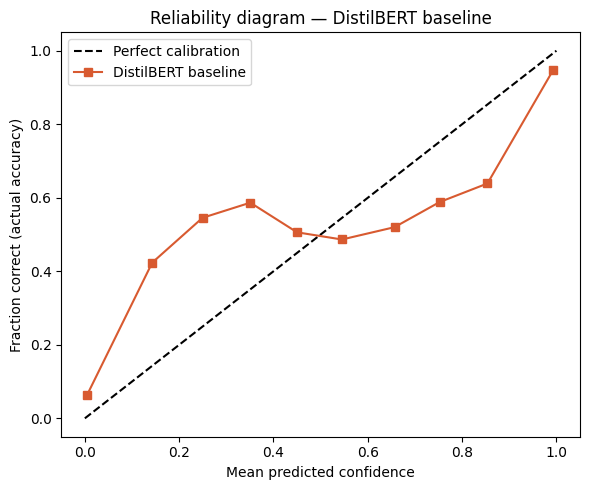

In [6]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_pos  = probs[:, 1].numpy()
label_np  = labels.numpy()

frac_pos, mean_conf_bins = calibration_curve(
    label_np,
    prob_pos,
    n_bins=10,
    strategy='uniform'
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.plot(mean_conf_bins, frac_pos, 's-', color='#D85A30', label='DistilBERT baseline')
ax.set_xlabel('Mean predicted confidence')
ax.set_ylabel('Fraction correct (actual accuracy)')
ax.set_title('Reliability diagram — DistilBERT baseline')
ax.legend()
plt.tight_layout()
#plt.savefig('../results/figures/calibration_curve.png', dpi=150)
plt.show()

In [7]:
from netcal.metrics import ECE

ece = ECE(bins=10)
ece_score = ece.measure(probs.numpy(), labels.numpy())
print(f"ECE (baseline): {ece_score:.4f}")

ECE (baseline): 0.0571


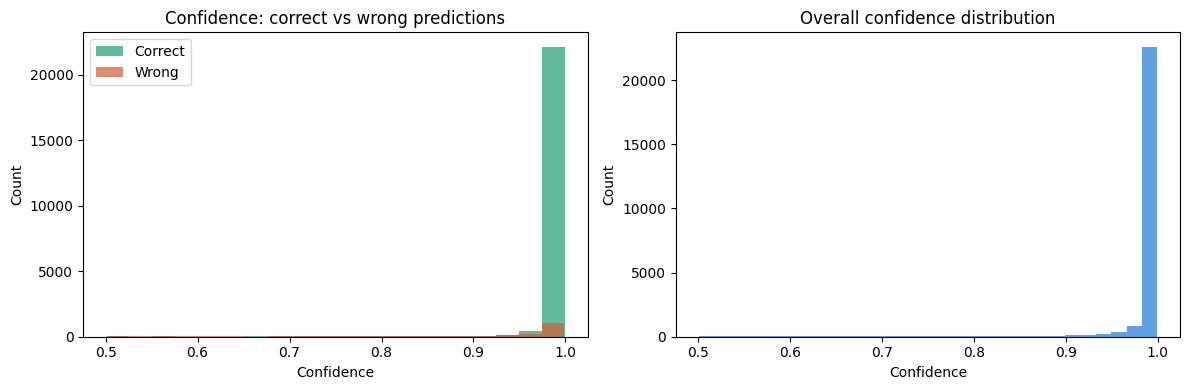

In [9]:
import seaborn as sns

correct_mask = (preds == labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    confs[correct_mask].numpy(),
    bins=20, color='#1D9E75', alpha=0.7, label='Correct'
)
axes[0].hist(
    confs[~correct_mask].numpy(),
    bins=20, color='#D85A30', alpha=0.7, label='Wrong'
)
axes[0].set_title('Confidence: correct vs wrong predictions')
axes[0].set_xlabel('Confidence')
axes[0].set_ylabel('Count')
axes[0].legend()

axes[1].hist(confs.numpy(), bins=30, color='#378ADD', alpha=0.8)
axes[1].set_title('Overall confidence distribution')
axes[1].set_xlabel('Confidence')
axes[1].set_ylabel('Count')

plt.tight_layout()
#plt.savefig('../results/figures/confidence_histograms.png', dpi=150)
plt.show()

In [10]:
correct_mask = (preds == labels)
wrong_mask = ~correct_mask

print("=" * 50)
print("BASELINE CALIBRATION SUMMARY")
print("=" * 50)
print(f"Total predictions:         {len(preds)}")
print(f"Accuracy:                  {correct_mask.float().mean():.4f}")
print(f"ECE:                       {ece_score:.4f}")
print(f"Mean confidence (all):     {confs.mean():.4f}")
print(f"Mean confidence (correct): {confs[correct_mask].mean():.4f}")
print(f"Mean confidence (wrong):   {confs[wrong_mask].mean():.4f}")
print(f"% predictions above 0.90:  {(confs > 0.90).float().mean()*100:.1f}%")
print(f"% predictions above 0.95:  {(confs > 0.95).float().mean()*100:.1f}%")
print(f"% predictions above 0.99:  {(confs > 0.99).float().mean()*100:.1f}%")
print(f"Min confidence:            {confs.min():.4f}")
print(f"Max confidence:            {confs.max():.4f}")

BASELINE CALIBRATION SUMMARY
Total predictions:         25000
Accuracy:                  0.9286
ECE:                       0.0571
Mean confidence (all):     0.9857
Mean confidence (correct): 0.9904
Mean confidence (wrong):   0.9244
% predictions above 0.90:  96.7%
% predictions above 0.95:  95.0%
% predictions above 0.99:  85.5%
Min confidence:            0.5005
Max confidence:            0.9991


In [12]:
wrong_and_very_confident = ((confs > 0.99) & wrong_mask).sum().item()
wrong_and_confident = ((confs > 0.90) & wrong_mask).sum().item()
total_wrong = wrong_mask.sum().item()

print(f"Total wrong predictions:                 {total_wrong}")
print(f"Wrong with >0.99 confidence:             {wrong_and_very_confident}")
print(f"% of wrong predictions above 0.99 conf: {wrong_and_very_confident/total_wrong*100:.1f}%")
print(f"Wrong with >0.90 confidence:             {wrong_and_confident}")
print(f"% of wrong predictions above 0.90 conf: {wrong_and_confident/total_wrong*100:.1f}%")

Total wrong predictions:                 1785
Wrong with >0.99 confidence:             643
% of wrong predictions above 0.99 conf: 36.0%
Wrong with >0.90 confidence:             1409
% of wrong predictions above 0.90 conf: 78.9%
